# 1. Lattices of a wallpaper group

For a chosen wallpaper group G, this notebook lists its **most Bravais-like lattices**, lets you pick one, and move its free parameters without leaving G.

**The rule: judge a lattice by its points alone.** A Bravais lattice is one point copied by a group of translations: every site is equivalent to every other, and nothing else is chosen. The same idea for a wallpaper group G:

1. **Points.** Take one point and copy it with all the operations of G (one *orbit*; the possible starting points are the Wyckoff positions of G). If one orbit is not enough, take two, then three.
2. **Exactly G, judged on the points.** The set of points, with no bonds drawn, must have the symmetry G and no more, with G's translations. Example: one orbit of p1 is a Bravais lattice, which always has a 2-fold rotation, so it is a lattice of p2 and not of p1.
3. **Simplest first.** Fewest kinds of site (orbits), then fewest sites per primitive cell.
4. **Bonds are not chosen.** Two sites are joined when their Voronoi cells share an edge (the Voronoi cell of a site is the region of the plane closer to it than to any other site). When four or more sites lie on one empty circle, which symmetry can force, they are left as one face (a square is not cut into two triangles). This network uses only distances, so it has exactly the symmetry of the points: bonds can neither add nor remove symmetry. It is always planar and connected, and every site has at least 3 bonds.
5. **One entry per network.** If a second set of points of G gives a network already listed, it is kept aside (`res.other[k]`).

**What to expect.**
* For p2, pmm, cmm, p4m and p6m the first entry is the Bravais lattice itself (one site per primitive cell). By rule 4 the oblique lattice is drawn as a triangular network (6 Voronoi neighbours), the rectangular and square ones with 4 bonds per site.
* p6m then gives the honeycomb, the kagome and the other classical uniform tilings, in order of sites per cell.
* For p1, pm, pg and cm no single orbit works: any single orbit of these groups has an extra 2-fold rotation. Their lists start with two or three kinds of site.
* The Voronoi network of a set of points can change when a parameter moves (four sites pass through a common circle). An entry shows the network met most often; the list says when there are others.

**Each list line also compares the network with the group:** "its own symmetry is this group", or "its own symmetry is N x larger" (the network, with the positions of its sites forgotten, has more symmetry than G; such lattices are kept in the lists).

**Status of the result: computational evidence.** Every choice of Wyckoff positions is tried, simplest first, at 48 random parameter values; a network met at fewer than 4 % of them is ignored, and one met at none is not found. The group of every listed lattice is checked by three routes (count of symmetry operations, the group finder of `wallpaper_lattices`, spglib). Two Wyckoff positions that give the same lattice (for p2: 1a, 1b, 1c, 1d) are listed once.

**Two other rules are available** (`RULE` below):
* `RULE = "sheet"`: the same condition on the points, but the bonds are chosen: among short bonds, the **fewest kinds of bond** that give a planar connected lattice with at least `MIN_DEGREE = 3` bonds at every site. Rank: kinds of site, kinds of bond, sites per cell, bonds per cell. This is the rule behind the hand-made sheet of named lattices (section 7): the Oblique lattice keeps 4 bonds per site, the Chiral Square is the first lattice of p4.
* `RULE = "bonds"`: as `"sheet"` but without the condition on the points, so the bonds may lower the symmetry (a lattice of p1 can then have 2 sites per cell).

In [1]:
# Setup: find the papertilling package (it sits in the folder above this notebook) and check what it needs.
import sys, pathlib, importlib.util
for _p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_p / "papertilling" / "__init__.py").exists():
        sys.path.insert(0, str(_p)); break
_kernel = "uv pip install --python '" + sys.executable + "' "
if importlib.util.find_spec("papertilling") is None:
    raise ImportError("papertilling not found. Keep this notebook inside the papertilling/notebooks folder, or install the "
                      "package into this kernel:  " + _kernel + "-e <path to the papertilling folder>")
_missing = [m for m in ("numpy", "scipy", "networkx", "matplotlib", "spglib") if importlib.util.find_spec(m) is None]
if _missing:
    raise ImportError("this kernel lacks " + ", ".join(_missing) + ". Install with:  " + _kernel + " ".join(_missing)
                      + "   (or run  %pip install " + " ".join(_missing) + "  in a cell)")
import papertilling
print("papertilling", papertilling.__version__, "| Python", sys.version.split()[0], "| numba:", importlib.util.find_spec("numba") is not None,
      "| sliders:", importlib.util.find_spec("ipywidgets") is not None)

papertilling 0.2.0 | Python 3.12.16 | numba: True | sliders: True


In [2]:
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from papertilling.lattice import load_catalogue, minimal_lattices, Lattice
from papertilling.groups import wyckoff_markdown
from papertilling.widgets import explore
from papertilling import named, named_lattices, gallery

## 1. Choose a group and list its lattices

`N` is the number of lattices to list. The stored lists hold the first 7 of every group and open instantly; with `N` above 7 the search runs now, going on to more kinds of site and more sites per cell until it has `N` (see the timings in `README.md`; it stops after 10 minutes and says so). Set `RECOMPUTE = True` to redo the search for one group (10 to 30 s for 7). With `RULE = "sheet"` or `"bonds"`, a `MIN_DEGREE` other than 3 searches again by itself (up to a minute).

Each entry: rank (kinds of site, kinds of bond, sites per cell, bonds per cell), the Wyckoff positions of the sites (ITA letter and site symmetry), the number of bonds per cell in each kind of bond, the free parameters; then its network (the face sizes round each kind of site, how the network's own symmetry compares with the group, whether other sets of points give the same network, and whether the Voronoi network changes with the parameters); then the one-line recipe that rebuilds it.

p4g: points-only rule. Tiers searched completely, in order: (1 kind(s) of site, 2 sites), (1 kind(s) of site, 4 sites), (1 kind(s) of site, 8 sites), (2 kind(s) of site, 4 sites), (2 kind(s) of site, 6 sites), (2 kind(s) of site, 8 sites), (2 kind(s) of site, 10 sites).
A choice of Wyckoff positions is kept when its points alone have exactly the symmetry p4g (tested at up to 48 random parameter values, seed 0); bonds = Voronoi neighbours; one entry per network. A network met in fewer than 4 % of the samples is ignored; one missed by every sample is not found.
p4g: first 7 of 7 lattices (points-only rule) found (8 drawings)  rank = (site orbits, bond orbits, sites/cell, bonds/cell)
#1 (1, 2, 4, 10)  sites 4c ..m  bond orbits [2, 8]  free ['t1']
    network: faces round a site 3.3.3.4.4; its own symmetry is this group
    Lattice.from_recipe(dict(group="p4g", sites=[(0.683, 0.183)], bonds=[((0.683, 0.183), (0.317, -0.183)), ((0.683, 0.183), (0.817, -0.317))], a=1))
#2 (1, 3, 8, 16)  site

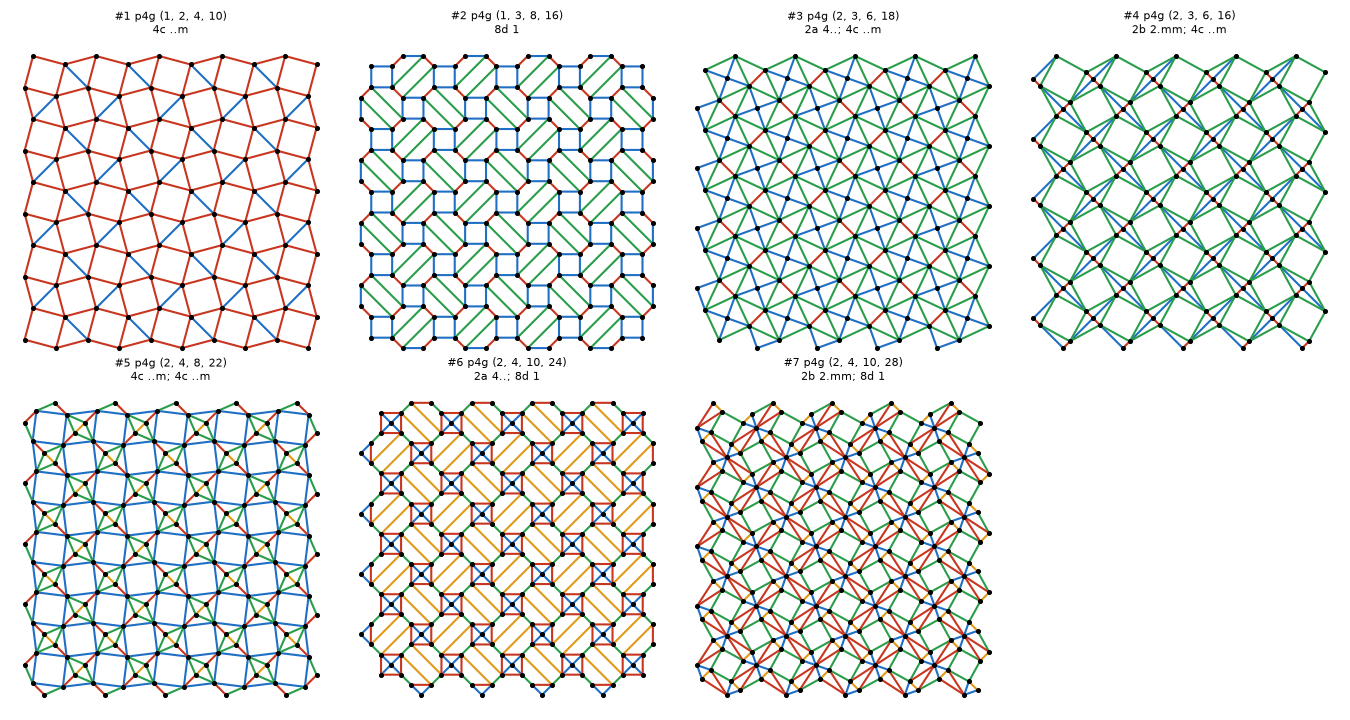

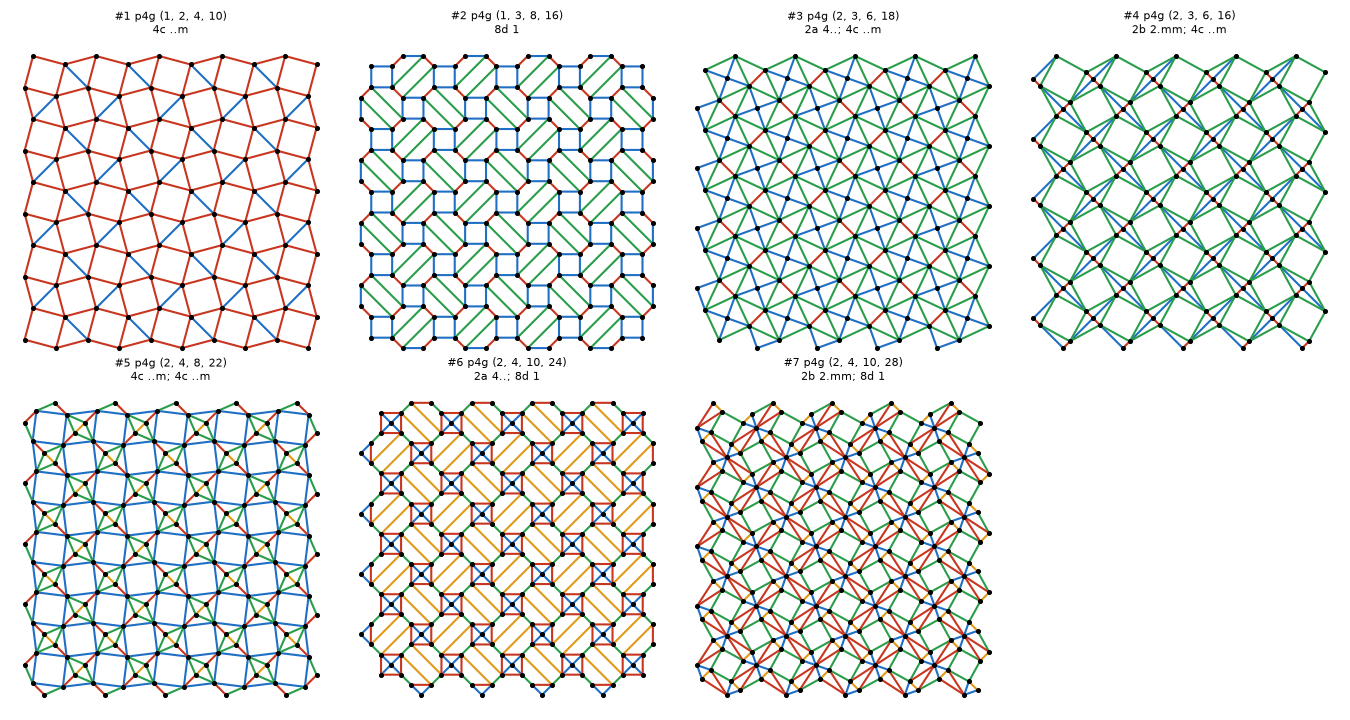

In [3]:
GROUP = "p4g"          # any of p1 p2 pm pg cm pmm pmg pgg cmm p4 p4m p4g p3 p3m1 p31m p6 p6m
N = 7                  # how many lattices to list. Up to 7 is instant (stored); more than 7 searches now.
RULE = "points"        # "points": points alone + Voronoi bonds (default); "sheet": points alone + fewest kinds of bond;
                       # "bonds": fewest kinds of site and bond, bonds may lower the symmetry
MIN_DEGREE = 3         # only for RULE = "sheet" or "bonds": fewest bonds per site, 3 (default) or 2
RECOMPUTE = False
if RECOMPUTE or N > 7 or (RULE != "points" and MIN_DEGREE != 3):
    res = minimal_lattices(GROUP, n=N, rule=RULE, min_degree=MIN_DEGREE)
else:
    res = load_catalogue(rule=RULE)[GROUP].take(N)
res.show()

In [4]:
print(res.coverage)

p4g: points-only rule. Tiers searched completely, in order: (1 kind(s) of site, 2 sites), (1 kind(s) of site, 4 sites), (1 kind(s) of site, 8 sites), (2 kind(s) of site, 4 sites), (2 kind(s) of site, 6 sites), (2 kind(s) of site, 8 sites), (2 kind(s) of site, 10 sites).
A choice of Wyckoff positions is kept when its points alone have exactly the symmetry p4g (tested at up to 48 random parameter values, seed 0); bonds = Voronoi neighbours; one entry per network. A network met in fewer than 4 % of the samples is ignored; one missed by every sample is not found.


## 2. The Wyckoff positions of the group

A **Wyckoff position** is a set of points with the same site symmetry (the operations of G that fix the point). Its **letter** is the one of the International Tables (ITA Vol. A), its **multiplicity** is the number of such points per conventional cell. A site on a rotation centre cannot move; a site on a mirror line can slide along it (one free parameter); a site in general position has two free parameters.

These tables were checked two independent ways: against the group's own operations, and against spglib's layer-group database (`tests/test_groups.py`).

In [5]:
display(Markdown(wyckoff_markdown(GROUP)))

**p4g** = p4gm, ITA plane group No. 12

| Wyckoff | site symmetry | kind | coordinates | occupied (site orbit) |
|---|---|---|---|---|
| 8d | `1` | general | (x,y) (-x,-y) (-y,x) (y,-x) (-x+1/2,y+1/2) (x+1/2,-y+1/2) (y+1/2,x+1/2) (-y+1/2,-x+1/2) |  |
| 4c | `..m` | line | (x,x+1/2) (-x,-x+1/2) (-x+1/2,x) (x+1/2,-x) |  |
| 2b | `2.mm` | point | (1/2,0) (0,1/2) |  |
| 2a | `4..` | point | (0,0) (1/2,1/2) |  |

## 3. Pick a lattice

`PICK` is the number in the list above. The table marks which Wyckoff positions it uses.

In [6]:
PICK = 1
L = res.lattices[PICK - 1]
print(L)
display(Markdown(wyckoff_markdown(GROUP, occupied=L.family)))
L.info()

Lattice(p4g, rank (1, 2, 4, 10): 1 site orbit(s) ['4c ..m'], 2 bond orbit(s), 4 sites and 10 bonds per primitive cell)


**p4g** = p4gm, ITA plane group No. 12

| Wyckoff | site symmetry | kind | coordinates | occupied (site orbit) |
|---|---|---|---|---|
| 8d | `1` | general | (x,y) (-x,-y) (-y,x) (y,-x) (-x+1/2,y+1/2) (x+1/2,-y+1/2) (y+1/2,x+1/2) (-y+1/2,-x+1/2) |  |
| 4c | `..m` | line | (x,x+1/2) (-x,-x+1/2) (-x+1/2,x) (x+1/2,-x) | **yes** (1) |
| 2b | `2.mm` | point | (1/2,0) (0,1/2) |  |
| 2a | `4..` | point | (0,0) (1/2,1/2) |  |

{'group': 'p4g',
 'rank': (1, 2, 4, 10),
 'site_orbits': ['4c ..m'],
 'sites_per_cell': 4,
 'bond_orbits': [{'bonds_per_cell': 2, 'length': 0.5176, 'joins': [1]},
  {'bonds_per_cell': 8, 'length': 0.5176, 'joins': [1]}],
 'bonds_per_cell': 10,
 'coordination': [5],
 'maxwell': -2,
 'connected': True,
 'free_parameters': ['t1'],
 'dsymbol_size': 5,
 'routes': {'count': 'p4g', 'legacy': 'p4g', 'spglib': 'p4g'}}

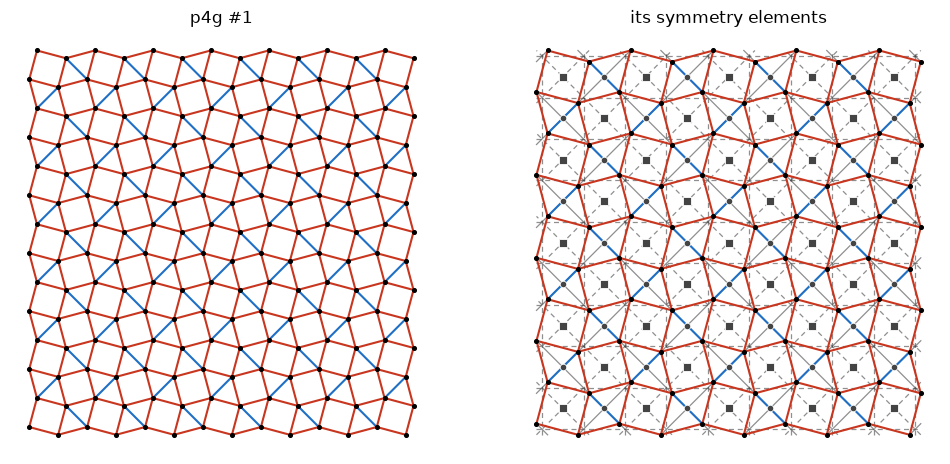

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
L.plot(n=3, ax=axs[0]); axs[0].set_title(f"{GROUP} #{PICK}")
L.family.plot(n=2, ax=axs[1], symmetry=True); axs[1].set_title("its symmetry elements")
plt.show()

## 4. Its free parameters

These are the coordinates G leaves free (a site on a mirror line slides along it; a site in general position moves in two directions) and the cell shape G leaves free (b, and gamma for oblique cells). Moving them **cannot lower** the symmetry below G. It can only **raise** it, on special values listed by `L.special()`: there the lattice gains symmetry and is no longer a lattice of G.

In [8]:
L.parameters()
print("\nspecial values (the group jumps up there):")
L.special();

  t1     = 0.433      site orbit 1: position along its mirror line, point = (1/4, -1/4) + t (1, 1)

special values (the group jumps up there):
no special locus found


### Move them with sliders

Each slider moves one free parameter, with the others held. Under each slider a bar shows its whole range:
* **hatched red = forbidden**: there the bonds would cross, a bond would pass through a site, two sites would coincide, or the lattice would become another tiling. The slider cannot be dragged into a forbidden part: its ends are the edges of the allowed stretch around the current value. The allowed stretch of one parameter depends on the others, so all the limits are recomputed after every move.
* **blue tick with a group name = a special value**, where the symmetry jumps up to that group (for instance, a value where a rectangle of sites becomes a square). A slider close to a special value snaps onto it, and the status line says which group the lattice has there.
* The cell parameters (`b`, `gamma`) are never forbidden (stretching or shearing the cell cannot make bonds cross); they only have special values.

The status line under the bars re-checks every move by the slow, independent route (group by two finders, planarity, bonds through sites, same tiling). For a lattice of the points-only rule a second line says whether the bonds are still the Voronoi-neighbour bonds of the points; if not, the drawing is still planar but the nearest-neighbour network of those points is another one.

`box.lattice()` gives the lattice at the slider values; `box.limits` and `box.special` hold the limits and the special values.

In [9]:
box = explore(L, n=2)

In [10]:
# the same by hand: a new Lattice; a warning is printed if the group, planarity or the tiling changes
name = L.family.names[-1] if L.family.names else None
if name:
    L2 = L.set(**{name: L.values[name] + 0.05})
    print(name, "->", L2.values[name], "| group still", L2.status["group"], "| same tiling:", L2.status["same_key"])

t1 -> 0.48300000000000004 | group still p4g | same tiling: True


## 5. Hand it to Notebooks 2 and 3

The line below rebuilds this lattice anywhere `papertilling` is imported. Paste it into the `LATTICE` cell of Notebooks 2 and 3.

In [11]:
L_now = box.lattice() if box is not None else L
print(L_now.code())

Lattice.from_recipe(dict(group="p4g", sites=[(0.683, 0.183)], bonds=[((0.683, 0.183), (0.317, -0.183)), ((0.683, 0.183), (0.817, -0.317))], a=1))


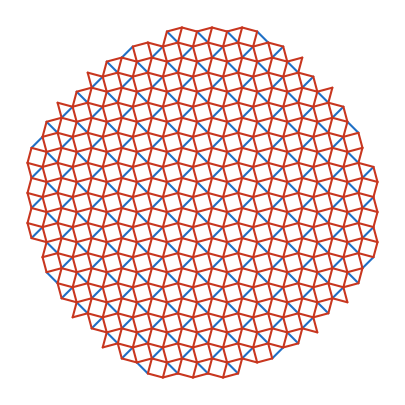

448 sites


In [12]:
# grow a finite piece of any size
from papertilling.legacy.wallpaper_lattices import WallpaperLattice
piece = WallpaperLattice(L_now.cell(), shape="disk", radius=6)
piece.plot(title=False); plt.show()
print(len(piece.positions), "sites")

## 6. All 17 groups at a glance

The most Bravais-like lattice of every group (its rank, Wyckoff positions, and the face sizes round each kind of site).

In [13]:
cat = load_catalogue()
for g, r in cat.items():
    e = r.lattices[0]
    print(f"{g:5s} rank {str(e.rank):15s} sites {'; '.join(e.wyckoff()):26s} faces round a site: {' | '.join(e.vertex_types())}")

p1    rank (3, 9, 3, 9)    sites 1a 1; 1a 1; 1a 1           faces round a site: 3.3.3.3.3.3
p2    rank (1, 3, 1, 3)    sites 1a 2                       faces round a site: 3.3.3.3.3.3
pm    rank (2, 5, 3, 7)    sites 1b .m.; 2c 1               faces round a site: 3.3.4.4 | 3.3.4.4.4.4
pg    rank (2, 6, 4, 12)   sites 2a 1; 2a 1                 faces round a site: 3.3.3.3.3.3
cm    rank (2, 5, 3, 9)    sites 2a .m.; 4b 1               faces round a site: 3.3.3.3.3.3
pmm   rank (1, 2, 1, 2)    sites 1a 2mm                     faces round a site: 4.4.4.4
pmg   rank (1, 3, 2, 6)    sites 2c .m.                     faces round a site: 3.3.3.3.3.3
pgg   rank (1, 4, 4, 12)   sites 4c 1                       faces round a site: 3.3.3.3.3.3
cmm   rank (1, 2, 1, 3)    sites 2a 2mm                     faces round a site: 3.3.3.3.3.3
p4    rank (1, 3, 4, 10)   sites 4d 1                       faces round a site: 3.3.3.4.4
p4m   rank (1, 1, 1, 2)    sites 1a 4mm                     faces round a si

## 7. The named lattices

Eighteen well-known lattices (Square, Kagomé, Shastry-Sutherland, ...) are stored by name, drawn on neat grids. `named("Kagomé")` gives one as a lattice of this package, so everything above and Notebooks 2 and 3 work on it; names are matched loosely (`"zig zag"`, `"kagome"`).

The table gives, for each: the group written on the original sheet, the **measured** group of the drawing, the kinds of site and of bond, and the faces round a site. Three drawings have more symmetry than their label (Straight, Shastry's Ladder, Brick); the last three rows are deformed versions that do have the labelled group.

In [14]:
rows = named_lattices()

name                           key                    sheet group kinds of site sites kinds of bond  bonds/site faces round a site
Oblique                        oblique                p2    p2                1     1             2  [4]        4.4.4.4
Elongated Triangular           elongated_triangular   cmm   cmm               1     2             3  [5]        3.3.3.4.4
Straight                       straight               p1    p2                2     4             5  [4, 5]     3.3.4.4.4 | 3.4.4.4  <- the drawing has more symmetry than the sheet's label
Square                         square                 p4m   p4m               1     1             1  [4]        4.4.4.4
Triangular                     triangular             p6m   p6m               1     1             1  [6]        3.3.3.3.3.3
Kagomé                         kagome                 p6m   p6m               1     3             1  [4]        3.3.6.6
Honeycomb                      honeycomb              p6m   p6m           

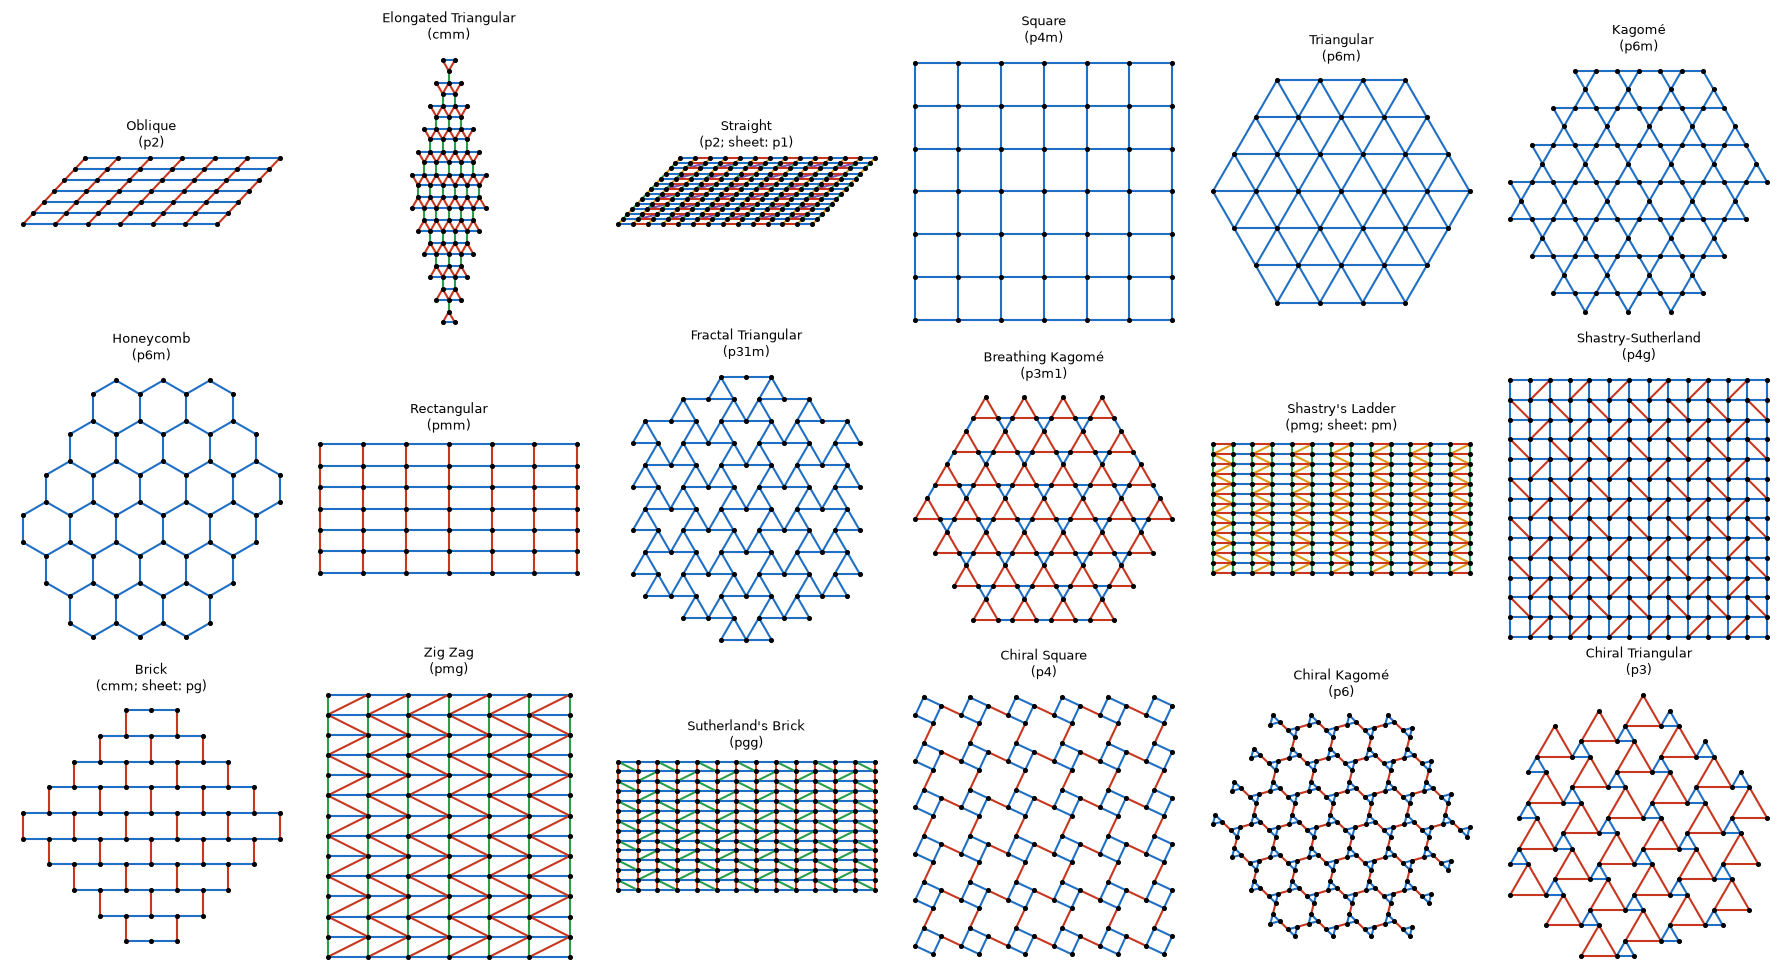

In [15]:
fig = gallery(); plt.show()

In [16]:
K = named("Shastry-Sutherland")
print(K)
print(K.code())          # paste this line into the LATTICE cell of Notebooks 2 and 3, or write L = named("Shastry-Sutherland") there

Lattice(p4g, rank (1, 2, 4, 10): 1 site orbit(s) ['4c ..m'], 2 bond orbit(s), 4 sites and 10 bonds per primitive cell)
Lattice.from_recipe(dict(group="p4g", sites=[(-1/4, 1/4)], bonds=[((3/4, 1/4), (3/4, -1/4)), ((3/4, 1/4), (5/4, 3/4))], a=2))


## 8. The lattice on other surfaces

**Which surfaces can carry a lattice without any defect?** Exactly the **flat** ones: the plane, the cylinder, the torus, the Moebius band and the Klein bottle. Each is the plane with some points glued together, and the gluing must be a symmetry of the lattice, so that every site keeps exactly the neighbourhood it had in the plane: same bonds, same lengths, same angles.
* **cylinder**: points a lattice vector **C** apart are glued (like the (n, m) of a nanotube); open at both ends;
* **torus**: points **T1** apart and points **T2** apart are glued (a finite crystal with periodic boundary conditions);
* **Moebius band** and **Klein bottle**: the gluing is a **glide** (reflect across a line, then slide along it), so the sheet comes back mirrored. That needs a mirror or glide line in the group: impossible for p1, p2, p3, p4, p6 (chiral lattices).

**Every other closed surface needs disclinations.** Walking round a disclination of Frank angle alpha turns a direction by 360 - alpha degrees instead of 360. The theorem of Gauss and Bonnet says that on a closed surface the Frank angles always add up to **360 deg x chi**, where chi = V - E + F (sites minus bonds plus faces) is the Euler characteristic:

| surface | chi | Frank angles must add up to |
|---|---|---|
| torus, Klein bottle | 0 | 0 (no defect needed) |
| sphere | 2 | +720 deg (for example 12 x 60 deg: the 12 pentagons of a football) |
| projective plane | 1 | +360 deg |
| surface with g holes (genus g) | 2 - 2g | -720 deg x (g - 1) |

Each picture below has two parts: the **flat piece** (the region of the plane that is glued up; edges with the same arrow are glued) and a **3D shape**. The flat piece is exact. The 3D shape is exact for the cylinder, but a flat torus has no undistorted shape in 3D (the doughnut stretches the bonds outside and squeezes them inside), and a Klein bottle must pass through itself in 3D.

`S.checks()` verifies each surface: no bond from a site to itself, no doubled bond, every site with its plane number of bonds (away from an open edge), and V - E + F = chi. Sizes are integer vectors in units of the primitive cell vectors of `L.cell()`.

**First, which surfaces this lattice can have.** `surface_table(SURF)` tries all eight and says, for each:
* **OK**: built, and every check passed;
* **IMPOSSIBLE**: proved from the lattice's symmetry, for every lattice of its group: no mirror or glide line means no Moebius band, Klein bottle or projective plane (those need a gluing that reverses orientation, and it must be a symmetry); no rotation centre (p1, pm, pg, cm) means no sphere or projective plane (a disclination must be a rotation of the lattice, so without rotations every Frank angle is 0 or negative, while Gauss-Bonnet needs +720 or +360 deg);
* **NOT FOUND**: this construction failed at every size and centre tried (for example, a corner would fold a bond onto itself). That is not a proof that the surface is impossible; the line says what was tried.

In [17]:
from papertilling.surfaces import surface_table
SURF = L_now                         # the lattice chosen above (or e.g. named("Kagomé"))
table = surface_table(SURF)          # about 10-60 s: sizes are retried for NOT FOUND

Surfaces for the lattice (p4g), 8.5 s:
  surface           sites  cones (Frank angles)     time   result
  torus               220  none                     0.2s   OK: torus: T1 (11, 0), T2 (0, -5)
  cylinder            240  none                     0.2s   OK: cylinder: wrap (12, 0), length 5
  Moebius band        328  none                     1.7s   OK: Moebius band: along 41, width 2, glide 0
  Klein bottle        204  none                     0.9s   OK: Klein bottle: along 17, across 6, glide 0
  sphere               24  8 x +90                  2.2s   OK: cube (sphere): size (1, 0), corners at centre class 2a(i) (face centre)
  projective plane      -  -                        2.8s   NOT FOUND: refused at every setting tried: a gluing of the net is not a symmetry of the lattice. Tried 6 setting(s): size=(1, 1) | size=(1, 0) | size=(2, 0) | size=(2, 1) | size=(2, 2) | size=(3, 0), at centres 2a(i), 2a(ii)
  genus 2             288  2 x -360                 0.2s   OK: genus 2 surface

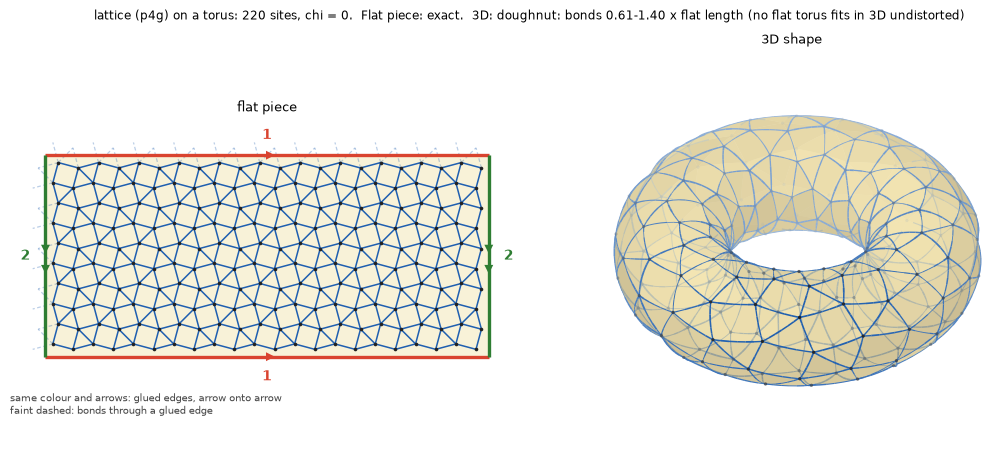

torus: V 220, E 550, F 330, V - E + F = 0 (chi 0); no loops True, no double bonds True, plane coordination kept True, faces >= 3 sides True  ->  OK


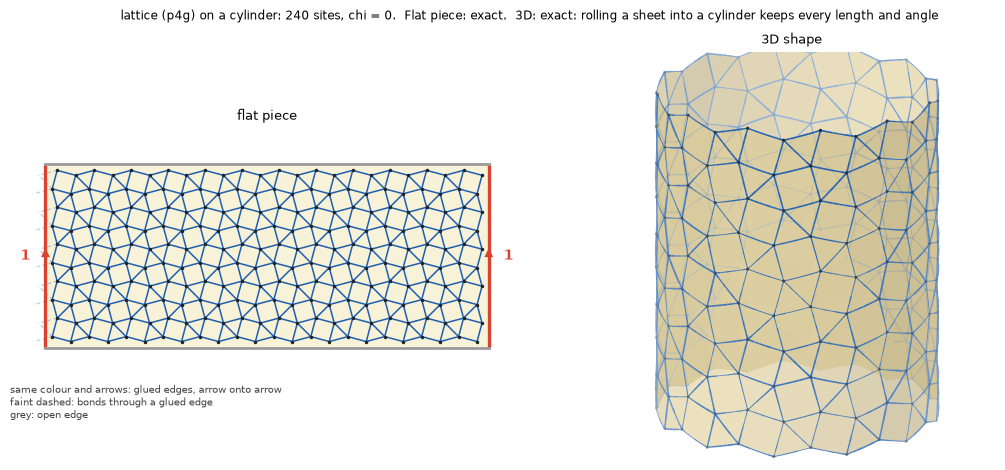

cylinder: V 240, E 564, F 324, V - E + F = 0 (chi 0); no loops True, no double bonds True, plane coordination kept True, faces >= 3 sides True  ->  OK


In [18]:
from papertilling.surfaces import torus, cylinder, mobius_band, klein_bottle, glides, sphere, projective_plane, genus_surface
SURF = L_now                        # the lattice chosen above (or e.g. named("Kagomé"))

for make in (torus, cylinder):      # sizes: torus(SURF, T1, T2), cylinder(SURF, wrap, length); default about 220 sites
    S = make(SURF)
    S.show(); plt.show()
    S.checks()

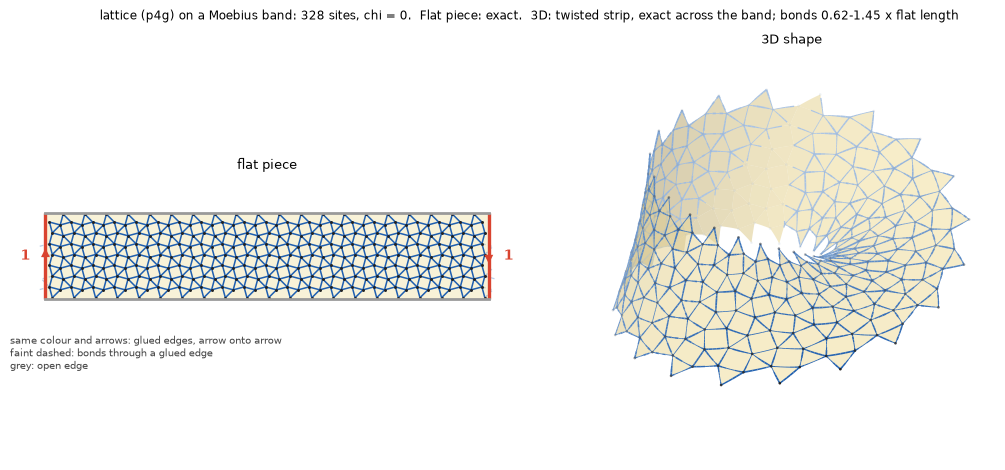

Moebius band: V 328, E 738, F 410, V - E + F = 0 (chi 0); no loops True, no double bonds True, plane coordination kept True, faces >= 3 sides True  ->  OK


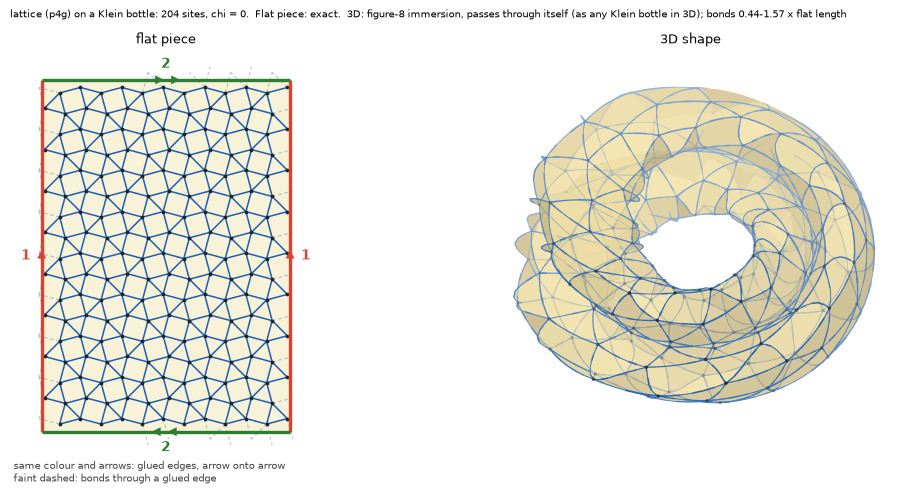

Klein bottle: V 204, E 510, F 306, V - E + F = 0 (chi 0); no loops True, no double bonds True, plane coordination kept True, faces >= 3 sides True  ->  OK


In [19]:
if glides(SURF):
    for make in (mobius_band, klein_bottle):
        S = make(SURF)
        S.show(); plt.show()
        S.checks()
else:
    print(f"{SURF.group} has no mirror or glide line: no Moebius band and no Klein bottle for this lattice.")

### The sphere: the lattice folded onto a polyhedron

The lattice is cut into congruent flat pieces whose corners sit at its own rotation centres of the highest order n, and the pieces are folded onto a polyhedron: an **icosahedron** for n = 6 (12 corners, each a disclination of +60 deg), a **cube** for n = 4 (8 x +90), an **octahedron** for n = 3 (6 x +120), a **pillow** for n = 2 (4 x +180). These are the smallest disclinations the lattice allows, and they add up to +720 deg, as Gauss-Bonnet requires. Away from the 12 (8, 6, 4) corners, every site has exactly its plane neighbourhood.

* `size=(h, k)`: the edge of a piece is the lattice vector h b1 + k b2 between two centres (like the (h, k) of fullerenes and virus capsids). Honeycomb (1, 1) is C60: 60 sites, 12 pentagons, 20 hexagons.
* `centre=`: which class of rotation centres carries the corners (`"1a"`, `"site"`, `"face centre"`). By default a face centre, so that no site loses a bond (honeycomb: the disclinations are pentagons). On the square lattice, `centre="site"` gives the cube (8 three-bond sites); the default, the plaquette centres, gives 8 triangles instead.
* Every gluing between pieces is tested: it must be a symmetry of the lattice, otherwise the construction is refused (a p3 lattice cannot fold onto an icosahedron, because a 60 deg rotation is not one of its symmetries; it folds onto an octahedron). A corner that would fold a bond onto itself, or shrink a face below 3 sides, is refused too. p1, pm, pg and cm have no rotation centre: no sphere.

The 3D shape is the polyhedron pushed onto a sphere, so bonds near the corners look shorter; the flat net on the left is exact.

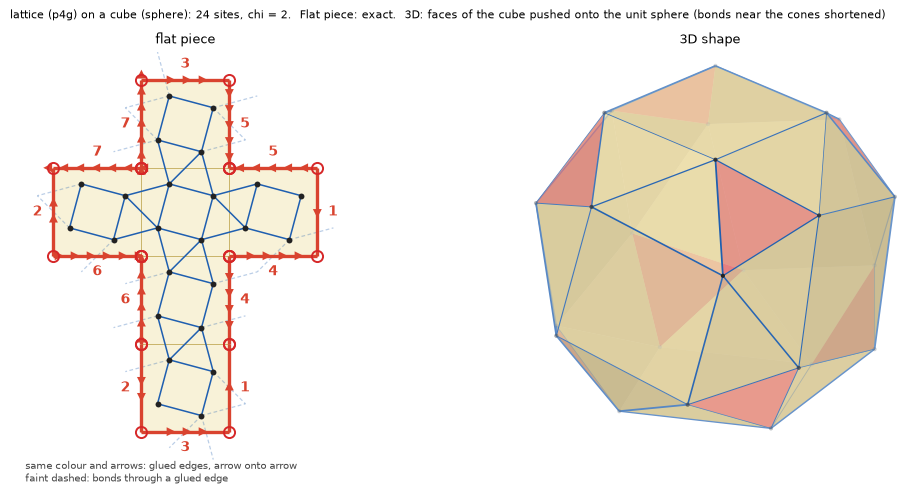

cube (sphere) of p4g: V 24, E 60, F 38, V - E + F = 2 (chi 2); faces {3: 32, 4: 6}; cones 8 x Frank [90.0] deg, sum 720 = 360 x chi True; no loops True, no double bonds True, faces >= 3 True, plane coordination away from cones True  ->  OK
8 disclinations: +90 deg at 2a(i) (face centre)


In [20]:
try:
    S = sphere(SURF)                 # e.g. sphere(SURF, size=(1, 1)), sphere(SURF, centre="site")
    S.show(); plt.show()
    S.checks()
    kinds = sorted({(c["label"], c["location"], c["angle"]) for c in S.cones})
    print(len(S.cones), "disclinations:", "; ".join(f"{a:+g} deg at {lab} ({loc})" for lab, loc, a in kinds))
except ValueError as err:
    print("no sphere for this lattice:", err)

### The projective plane

A closed surface with chi = 1: a sphere with every point glued to the opposite point. Here: half of the polyhedron (a hemi-icosahedron, hemi-cube, hemi-octahedron or hemi-pillow), with opposite edges glued after a **reflection**. So it carries half as many disclinations (+360 deg in total), and it needs a reflection or glide among the lattice's symmetries that matches the gluing: refused for chiral lattices (p2, p3, p4, p6) and for groups without rotations. Honeycomb (1, 1) gives 30 sites, 6 pentagons and 10 hexagons. The 3D picture shows the double cover (a sphere): the two sites with the same colour are the same site of the projective plane.

In [21]:
try:
    S = projective_plane(SURF)       # default size (1, 1); try (1, 0) or (2, 0) if refused
    S.show(); plt.show()
    S.checks()
except ValueError as err:
    print("no projective plane at this size:", err)

no projective plane at this size: projective plane of p4g not found: the hemi-cube construction at size (1, 1) was refused at every order-4 centre class tried [tried: size (1, 1), centre 2a(i): hemi-cube (projective plane) refused for p4g: 3 of 6 gluings of this net are not symmetries of the lattice: sides (0, 2) -> (2, 3): a glide by -2.8284 in the line through [0.5, 0.5] along [-0.7071, 0.7071] (site 0 of the cell lands on no site); sides (0, 3) -> (1, 2): a glide by -2.8284 in the line through [-0.5, 0.5] along [-0.7071, -0.7071] (site 0 of the cell lands on no site); sides (1, 3) -> (2, 2): a glide by -3.0000 in the line through [0.5, -0.0] along [0.0, 1.0] (site 0 of the cell lands on no site) (try another size or centre); size (1, 1), centre 2a(ii): hemi-cube (projective plane) refused for p4g: 3 of 6 gluings of this net are not symmetries of the lattice: sides (0, 2) -> (2, 3): a glide by -2.8284 in the line through [1.0, 1.0] along [-0.7071, 0.7071] (site 0 of the cell lands on

### Surfaces with g holes (genus g)

They need negative disclinations adding up to -720 deg x (g - 1). The construction used here works for every lattice, including p1: take two copies (sheets) of a torus of the lattice, cut both along g - 1 slits, and glue each side of a slit to the opposite side on the other sheet. Going once round an end of a slit takes you to the other sheet; going round twice brings you back, after 720 deg instead of 360 deg. So each slit end is a disclination of **-360 deg**, sitting in a face, which becomes one face with twice as many sides. Every site keeps its plane neighbourhood. There are 2(g - 1) slit ends, and 2(g - 1) x (-360) = -720 (g - 1), as required.

The picture is the two sheets side by side with the slits (red), their ends (stars) and the bonds that change sheet; a genus-g surface with this geometry has no simple 3D shape.

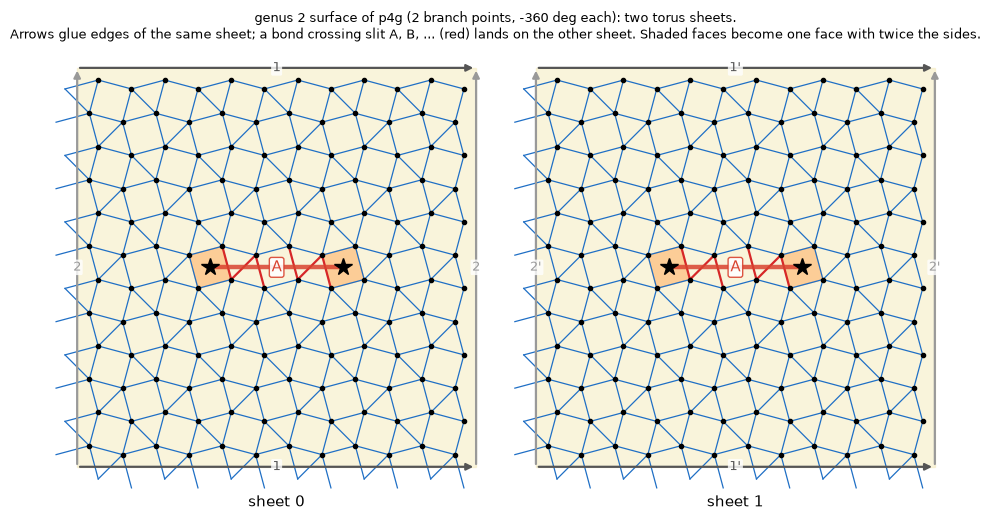

genus 2 surface: V 288, E 720, F 430, V - E + F = -2 (chi -2); 2 branch points, Frank angles add to -720 = 360 x -2: True; no loops True; no double bonds True; plane coordination True; faces at least 3 True; connected True; two faces per bond True; branch faces doubled True; other faces twice True  ->  OK


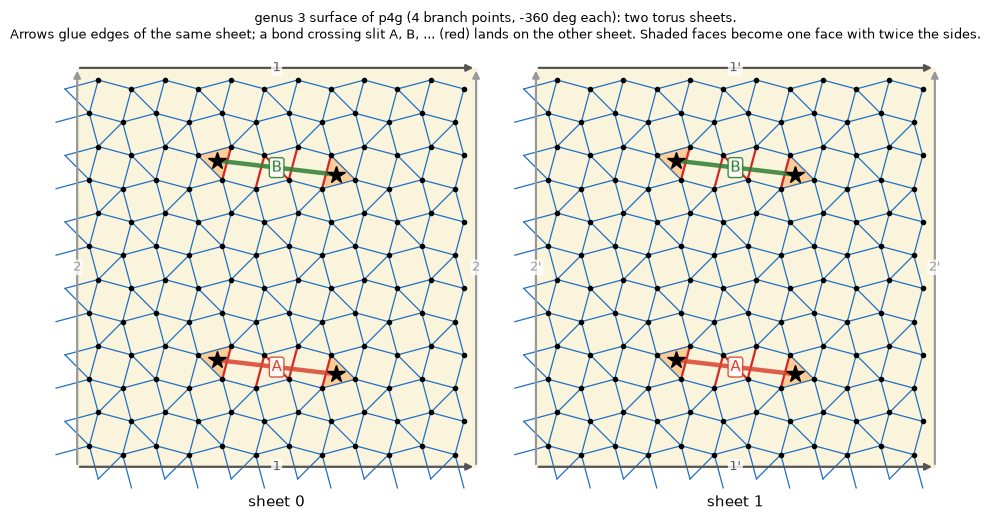

genus 3 surface: V 288, E 720, F 428, V - E + F = -4 (chi -4); 4 branch points, Frank angles add to -1440 = 360 x -4: True; no loops True; no double bonds True; plane coordination True; faces at least 3 True; connected True; two faces per bond True; branch faces doubled True; other faces twice True  ->  OK


In [22]:
for g in (2, 3):
    try:
        S = genus_surface(SURF, g=g)             # torus_size=(6, 6) cells by default; enlarge it for more holes
        S.plot_net(); plt.show()
        S.checks()
    except ValueError as err:
        print(f"genus {g}: refused:", err)